In [6]:
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [8]:
births = Table.read_table('baby.csv')

### A bell shape tells us more about a distribution

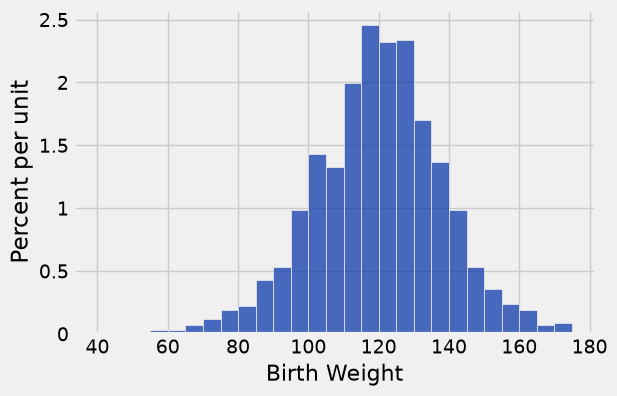

In [14]:
births.hist('Birth Weight', bins=np.arange(40, 180, 5))

In [27]:
def chebyshev(num_SDs):
    z = num_SDs
    return 1 - 1/z**2

In [28]:
birth_weight_mean = np.average(births.column('Birth Weight'))
birth_weight_mean

119.46252129471891

In [29]:
birth_weight_sd = np.std(births.column('Birth Weight'))
birth_weight_sd

18.320863702202779

### STD is the root mean square of the difference

### within 1 SD

In [30]:
chebyshev(1)

0.0

In [35]:
births.where('Birth Weight', are.between(birth_weight_mean - birth_weight_sd,
                                         birth_weight_mean + birth_weight_sd)).num_rows/births.num_rows

0.692504258943782

### Within 2 SD

In [33]:
births.where('Birth Weight', are.between(birth_weight_mean - 2 * birth_weight_sd,
                                         birth_weight_mean + 2 * birth_weight_sd)).num_rows/births.num_rows

0.948892674616695

### Within 3 SD

In [36]:
births.where('Birth Weight', are.between(birth_weight_mean - 3 * birth_weight_sd,
                                         birth_weight_mean + 3 * birth_weight_sd)).num_rows/births.num_rows

0.995741056218058

### Central Limit Theorem

- describes how the normal distribution os connected to random sample averages
- we care about these because they model populations

In [42]:
united = Table.read_table('united.csv')
united.show(6)

Date,Flight Number,Destination,Delay
6/1/15,73,HNL,257
6/1/15,217,EWR,28
6/1/15,237,STL,-3
6/1/15,250,SAN,0
6/1/15,267,PHL,64
6/1/15,273,SEA,-6


In [43]:
population_parameter = np.mean(united.column('Delay'))
population_parameter

16.658155515370705

In [54]:
def one_sample_mean(sample_size):
    '''
    takes a sample from the population and computes the mean
    '''
    sample_flights = united.sample(sample_size)
    return np.mean(sample_flights.column('Delay'))

In [55]:
def sample_means(sample_size, num_samples):
    means = make_array()
    for i in np.arange(num_samples):
        mean = one_sample_mean(sample_size)
        means = np.append(means, mean)
    return means

In [58]:
def plot_sample_mean_distribution(sample_size):
    means = sample_means(sample_size, 10000)
    means_table = Table().with_column('sample means', means)
    means_table.hist()

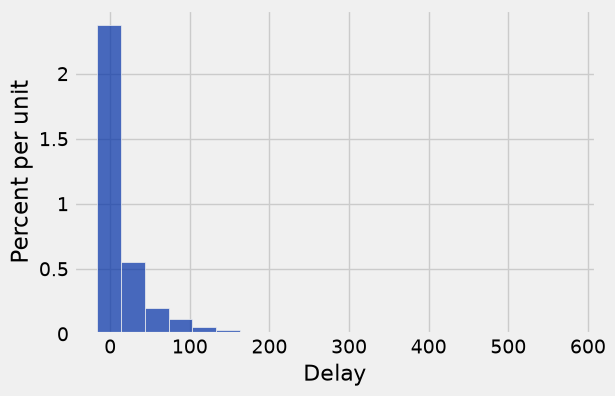

In [63]:
united.hist('Delay', bins=20)

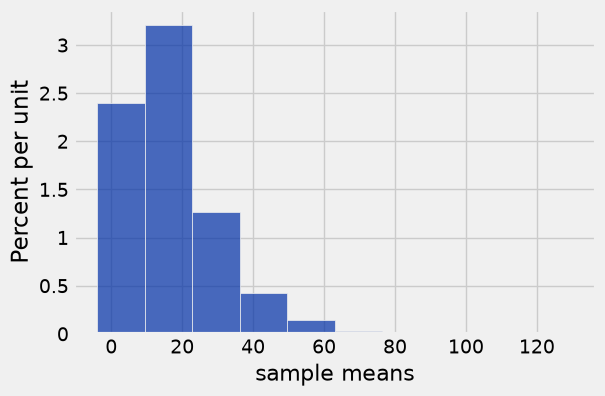

In [64]:
plot_sample_mean_distribution(10)

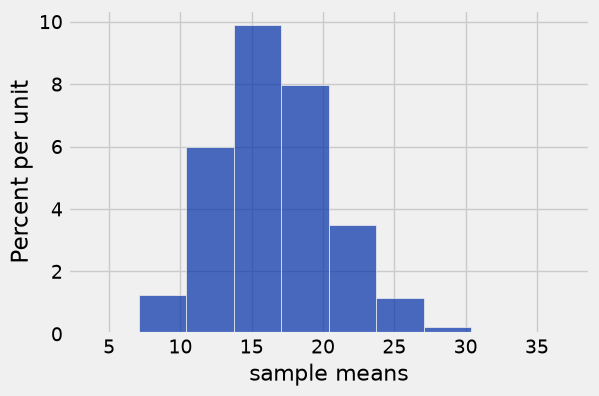

In [65]:
plot_sample_mean_distribution(100)

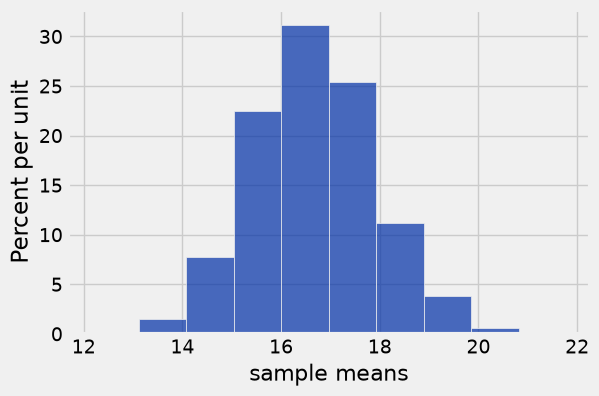

In [66]:
plot_sample_mean_distribution(1000)

### Central limit theorem

- if the sample is large
- drawn at random with replacement

then, regaurdless of the distribution of the population the probability distribution of the sample average is roughly normal

### Distribution of the sample average

In [82]:
sample_means_400 = sample_means(400, 10000)
sample_averages_average = np.average(sample_means_400)
sample_averages_average

16.656250249999999

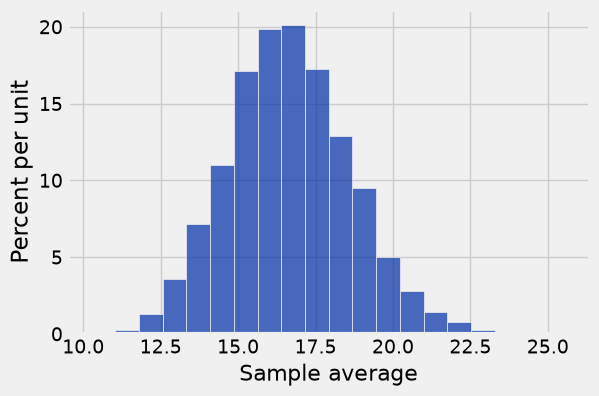

In [83]:
t = Table().with_column('Sample average', sample_means_400)
t.hist(bins=20)

In [87]:
sample_means_900 = sample_means(900, 10000)
sample_averages_average = np.average(sample_means_900)
sample_averages_average

16.647097000000002

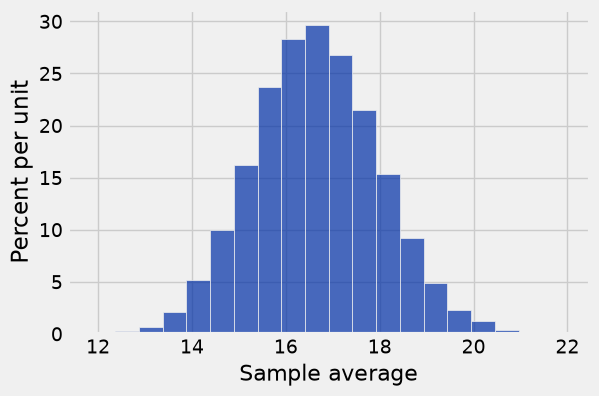

In [88]:
t = Table().with_column('Sample average', sample_means_900)
t.hist(bins=20)

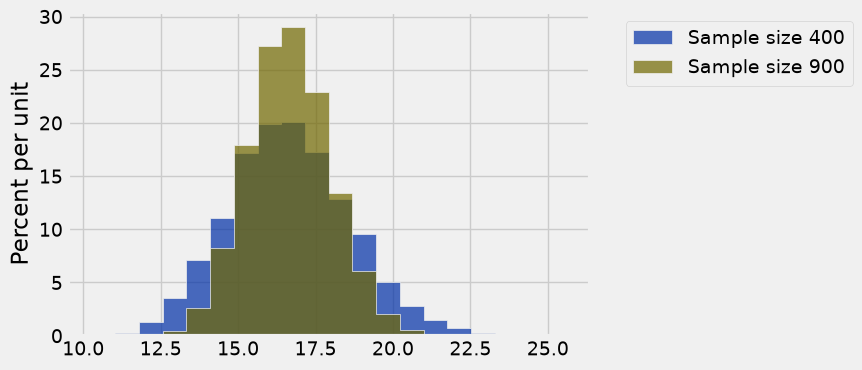

In [101]:
t = Table().with_columns(
    'Sample size 400', sample_means_400,
    'Sample size 900', sample_means_900
)
t.hist(bins=20)

### Qunatify the relationship between the width of the bell shape and sample size?

In [97]:
def plot_sample_means(sample_size):
    means = sample_means(sample_size, 10000)
    means_table = Table().with_column('sample means', means)
    pop_sd = np.std(united.column('Delay'))
    sample_means_sd = np.std(means)
    print('Population SDs:', pop_sd)
    print('Std of sample means:', sample_means_sd)
    print('Population SD / SD of sample means', pop_sd/sample_means_sd)
    
    means_table.hist(bins = 20)
    plt.xlabel('Sample Means')

Population SDs: 39.4801998516
Std of sample means: 1.95594042234
Population SD / SD of sample means 20.1847660597


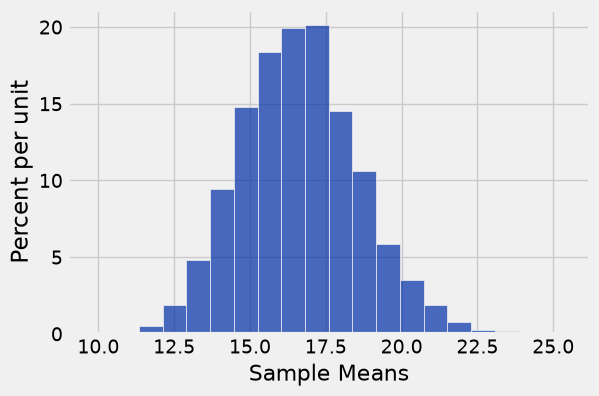

In [98]:
plot_sample_means(400)

Population SDs: 39.4801998516
Std of sample means: 1.57383436167
Population SD / SD of sample means 25.0853589254


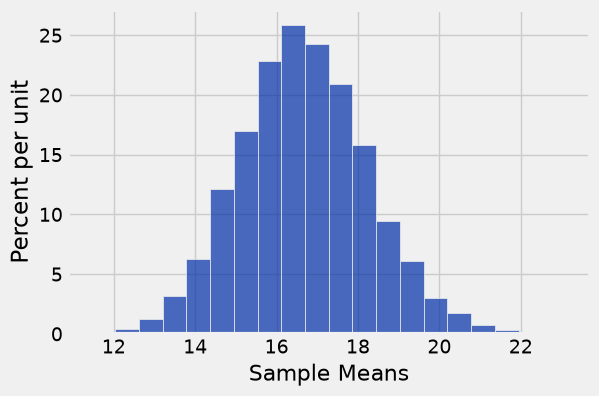

In [100]:
plot_sample_means(625)